In [8]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal


In [9]:
class QuadState(TypedDict):
    a:int
    b:int
    c:int 

    discriminant:float
    equation:str
    result:str

In [10]:
def show_equation(state: QuadState)-> QuadState:
    equation = f"""{state["a"]}x² + {state["b"]}x + {state["c"]} = 0"""
    return {'equation':equation}

def calculate_discriminant(state: QuadState) -> QuadState:
    discri = state['b']**2 - 4*state['a']*state['c']
    return {'discriminant':discri}

def real_root(state:QuadState)->QuadState:
    root1 = (-state['b'] + state['discriminant']**0.5)/2*state['a']
    root2 = (-state['b'] - state['discriminant']**0.5)/2*state['a']

    result = f""" The roots are {root1} and {root2}"""
    return {'result':result}

def repeated_root(state:QuadState)->QuadState:
    root = (-state['b'])/2*state['a']
    
    result = f"""Only repeating root is {root}"""
    return {'result':result}

def no_real_root(state:QuadState)->QuadState:
    
    result = f"""No Real Roots"""
    return {'result':result}



In [11]:
def check_condition(state:QuadState)->Literal['no_real_root','real_root','repeated_root']:
    if state['discriminant']>0:
        return "real_root"
    elif state['discriminant']==0:
        return "repeated_root"
    else:
        return "no_real_root"

In [12]:
graph = StateGraph(QuadState)

graph.add_node('show_equation',show_equation)
graph.add_node('calculate_discriminant',calculate_discriminant)
graph.add_node('no_real_root',no_real_root)
graph.add_node('real_root',real_root)
graph.add_node('repeated_root',repeated_root)

graph.add_edge(START,'show_equation')
graph.add_edge('show_equation','calculate_discriminant')
graph.add_conditional_edges('calculate_discriminant',check_condition)
graph.add_edge('real_root',END)
graph.add_edge('no_real_root',END)
graph.add_edge('repeated_root',END)


workflow = graph.compile()


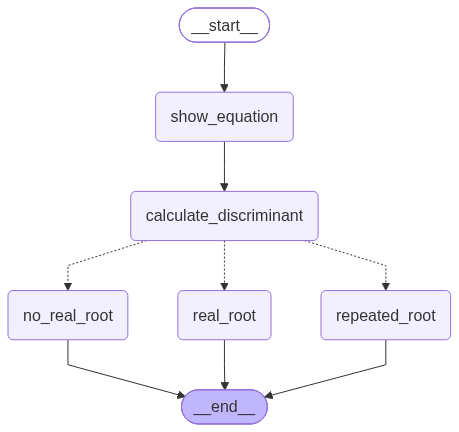

In [13]:
workflow 

In [17]:
initial_state = {
    'a': 2, 
    'b': 4,
    'c': 4
}

workflow.invoke(initial_state)

{'a': 2,
 'b': 4,
 'c': 4,
 'discriminant': -16,
 'equation': '2x² + 4x + 4 = 0',
 'result': 'No Real Roots'}